# Yaw NN — neural-network model of the yaw axis

Advanced task 1 (*make the drone rotate on itself at the end of step 2*) needs a model of the yaw axis.
Same job and same structure as `nn_test.ipynb`, on new data generated with `matlab_yaw/gen_yaw_data.m`:

* the trained altitude SAC flies random altitude staircases (so the collective thrust `u_coll` varies),
* the yaw command `delta` is excited with random doublets: $u_{1,3} = u_{coll} + \delta$, $u_{2,4} = u_{coll} - \delta$
  (M1 and M3 turn the drone one way, M2 and M4 the other),
* 150 flights of 60 s: runs 1-130 with `g_noise = 0.01` (like the course data), runs 131-150 without noise.

**Same structure as the altitude model.** There, the network predicts the vertical acceleration $a_z$ and
$v_z$, $z$ are integrated. Here it predicts the **yaw acceleration** $\dot w_z$ (output `w_dot_z` of
`UAV_model.slx`) and $w_z$, $\psi$ are integrated (known physics, not learned):

$$\dot w_z[k] \;=\; F\big(\dot w_z[k-1],\ \delta[k-1],\ u_{coll}[k-1]\big)$$

In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

Ts = 0.05
plt.rcParams['figure.figsize'] = (11, 3.2); plt.rcParams['axes.grid'] = True
np.set_printoptions(suppress=True, precision=4)

## 1. Load and check

Physical bounds first, as for the altitude data. Then a consistency check between two outputs of the
simulator: integrating `w_dot_z` must give back `wz`.

In [2]:
files = sorted(glob.glob('matlab_yaw/data/yaw_run_*.csv'))
runs = [pd.read_csv(f) for f in files]
bad = [i for i, r in enumerate(runs)
       if r.isna().any().any() or r.wz.abs().max() > 15 or r.w_dot_z.abs().max() > 100
       or r.z.min() < -0.6 or r.z.max() > 1.2]
print(f'{len(runs)} flights of {len(runs[0])} samples, {len(bad)} rejected {bad}')

train = [i for i in range(110) if i not in bad]
val   = [i for i in range(110, 130) if i not in bad]       # noisy, never used to fit
test  = [i for i in range(130, 150) if i not in bad]       # clean, never used to fit
print(f'{len(train)} train / {len(val)} validation (g_noise 0.01) / {len(test)} test (no noise)')

all_ = pd.concat([runs[i] for i in train])
print(f'u_coll in [{all_.u_coll.min():.2f}, {all_.u_coll.max():.2f}],  delta in [{all_.delta.min():.3f}, {all_.delta.max():.3f}],'
      f'  w_dot_z std {all_.w_dot_z.std():.2f} rad/s^2,  wz std {all_.wz.std():.2f} rad/s')

r = runs[test[0]]; a = r.w_dot_z.values
wz_int = r.wz.values[0] + np.concatenate([[0], np.cumsum(Ts * (a[1:] + a[:-1]) / 2)])
print(f'consistency: integral of w_dot_z vs wz, rms {np.sqrt(np.mean((wz_int - r.wz.values) ** 2)):.4f} rad/s over 60 s')

150 flights of 1201 samples, 0 rejected []
110 train / 20 validation (g_noise 0.01) / 20 test (no noise)
u_coll in [-0.33, 0.98],  delta in [-0.148, 0.148],  w_dot_z std 4.95 rad/s^2,  wz std 1.65 rad/s
consistency: integral of w_dot_z vs wz, rms 0.0116 rad/s over 60 s


## 2. Sampling period and structure

Least squares on the training flights: which lags are needed? The command $\delta[k]$ is held during
$[t_k, t_{k+1}]$, so it can only act on $\dot w_z[k+1]$: as for the thrust, **one sample of input delay**.
A first-order motor gives one lag of $\dot w_z$; the pole then gives the motor time constant, and $T_s$
must be small compared to it.

In [3]:
def arx(lags):
    def X(r):
        a, d = r.w_dot_z.values, r.delta.values; k = np.arange(3, len(r))
        return np.column_stack([a[k-1]] + [d[k-j] for j in lags]), a[k]
    XY = [X(runs[i]) for i in train]
    th = np.linalg.lstsq(np.vstack([x for x, _ in XY]), np.concatenate([y for _, y in XY]), rcond=None)[0]
    e = np.sqrt(np.mean(np.concatenate([x @ th - y for x, y in (X(runs[i]) for i in test)]) ** 2))
    return th, e

for lags in ([0], [1], [1, 2], [0, 1]):
    th, e = arx(lags)
    print(f'delta lags {str(lags):7s} theta = {th}   one-step error (test) {e:.3f} rad/s^2')
th, _ = arx([1])
print(f'\npole {th[0]:.4f} -> tau = {-Ts / np.log(th[0]):.3f} s,  static gain {th[1] / (1 - th[0]):.1f} rad/s^2 per unit of delta')

delta lags [0]     theta = [ 0.8937 26.602 ]   one-step error (test) 1.176 rad/s^2
delta lags [1]     theta = [ 0.7787 38.1158]   one-step error (test) 0.110 rad/s^2
delta lags [1, 2]  theta = [ 0.7787 38.1202 -0.008 ]   one-step error (test) 0.110 rad/s^2
delta lags [0, 1]  theta = [ 0.7787  0.0228 38.0971]   one-step error (test) 0.110 rad/s^2

pole 0.7787 -> tau = 0.200 s,  static gain 172.2 rad/s^2 per unit of delta


Only $\delta[k-1]$ matters ($\delta[k]$ and $\delta[k-2]$ get coefficients $\approx 0$). The pole is
$0.779$, i.e. $\tau = -T_s/\ln 0.779 \approx 0.20$ s, **the same time constant as the thrust** (0.20 s
in the tanh altitude model): it is the motor dynamics, the same motors seen through a different
combination. $T_s = 0.05$ s gives 4 samples per time constant (the usual rule is 4-10): enough.

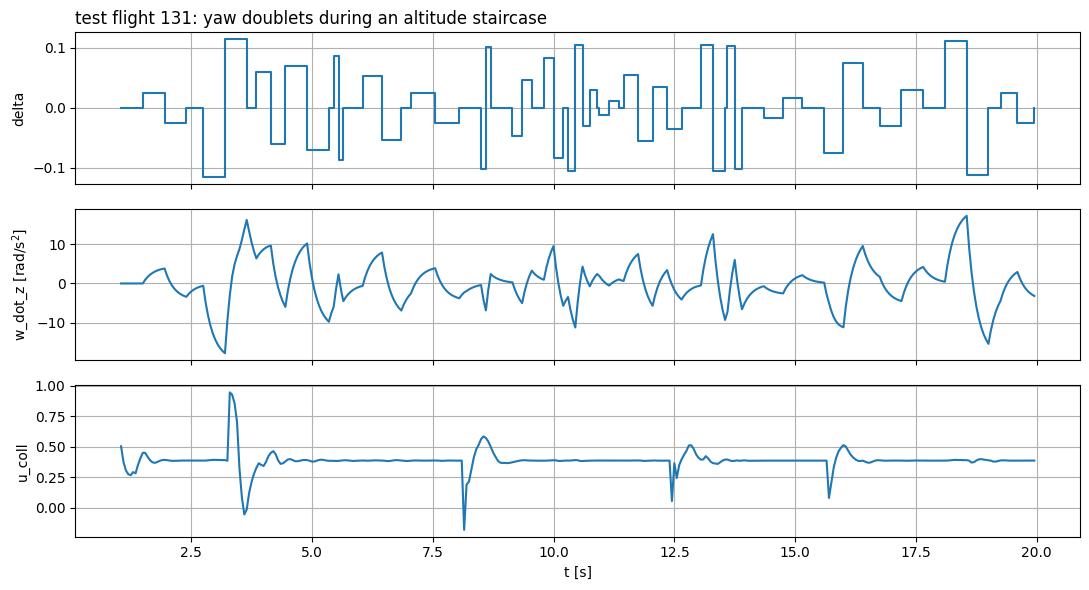

In [4]:
fig, ax = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
r = runs[test[0]]; s = (r.t > 1) & (r.t < 20)
ax[0].step(r.t[s], r.delta[s], where='post'); ax[0].set_ylabel('delta')
ax[1].plot(r.t[s], r.w_dot_z[s]); ax[1].set_ylabel('w_dot_z [rad/s$^2$]')
ax[2].plot(r.t[s], r.u_coll[s]); ax[2].set_ylabel('u_coll'); ax[2].set_xlabel('t [s]')
ax[0].set_title(f'test flight {test[0] + 1}: yaw doublets during an altitude staircase', loc='left')
plt.tight_layout(); plt.show()

## 3. Three models, same structure

| model | input | why |
|---|---|---|
| **linear** (least squares) | $\delta[k-1]$ | yaw torque proportional to $\delta$ |
| **tanh** (Hammerstein, least squares) | $g = \tanh(u_{coll}+\delta) - \tanh(u_{coll}-\delta)$ | each motor input goes through a `tanh` in `UAV_model.slx`: the torque is a difference of two saturated commands, so the gain **depends on `u_coll`** |
| **neural network** (MLP, 16 tanh units) | $\delta[k-1]$, $u_{coll}[k-1]$ raw | learns the map from data, no structure imposed |

All three take $\dot w_z[k-1]$ as the state, like `az[k-1]` in `nn_test`.

**Symmetry.** Reversing $\delta$ reverses the rotation: $F(-\dot w_z, -\delta, u) = -F(\dot w_z, \delta, u)$.
The linear and tanh models have it by construction (no intercept, $g$ odd in $\delta$). The network does
not, and a bias at rest of $10^{-2}$ rad/s$^2$ (invisible one-step) becomes ~1000 deg of $\psi$ in 60 s
after the double integration. So the network is trained on the data **and its mirror image**, and evaluated
as $\tfrac12\big(F(x) - F(\bar x)\big)$ ($\bar x$: signs of $\dot w_z$ and $\delta$ flipped): its bias
at rest is then exactly 0.

In [5]:
def g(u, d):
    return np.tanh(u + d) - np.tanh(u - d)

def features(r, kind):
    a, d, u = r.w_dot_z.values, r.delta.values, r.u_coll.values
    k = np.arange(1, len(r))
    if kind == 'linear':
        X = np.column_stack([a[k-1], d[k-1]])
    elif kind == 'tanh':
        X = np.column_stack([a[k-1], g(u[k-1], d[k-1])])
    else:
        X = np.column_stack([a[k-1], d[k-1], u[k-1]])
    return X, a[k]

def dataset(rows, kind):
    XY = [features(runs[i], kind) for i in rows]
    return np.vstack([x for x, _ in XY]), np.concatenate([y for _, y in XY])

theta = {}
for kind in ('linear', 'tanh'):
    X, y = dataset(train, kind)
    theta[kind] = np.linalg.lstsq(X, y, rcond=None)[0]
    print(f'{kind:7s} theta = {theta[kind]}')

FLIP = np.array([-1, -1, 1.0])                       # mirror image: w_dot_z, delta -> -w_dot_z, -delta
X_tr, y_tr = dataset(train, 'nn')
X_tr, y_tr = np.vstack([X_tr, X_tr * FLIP]), np.concatenate([y_tr, -y_tr])
sx = StandardScaler(with_mean=False).fit(X_tr); sy = StandardScaler(with_mean=False).fit(y_tr.reshape(-1, 1))
net = MLPRegressor(hidden_layer_sizes=(16,), activation='tanh', solver='adam', learning_rate_init=1e-3,
                   batch_size=256, max_iter=200, early_stopping=True, n_iter_no_change=10,
                   validation_fraction=0.15, random_state=0)
net.fit(sx.transform(X_tr), sy.transform(y_tr.reshape(-1, 1)).ravel())
print(f'NN: {X_tr.shape[0]:,} samples (with mirror), stopped after {net.n_iter_} epochs, '
      f'{sum(c.size for c in net.coefs_) + sum(i.size for i in net.intercepts_)} parameters')

def nn_raw(X):
    return sy.inverse_transform(net.predict(sx.transform(X)).reshape(-1, 1)).ravel()

def nn_predict(X):                                   # antisymmetric by construction: zero bias at rest
    return (nn_raw(X) - nn_raw(X * FLIP)) / 2

def predict(kind, X):
    return nn_predict(X) if kind == 'nn' else X @ theta[kind]

print('NN acceleration at rest (delta = 0, hover):', nn_predict(np.array([[0, 0, 0.39]]))[0], 'rad/s^2')

linear  theta = [ 0.7787 38.1158]
tanh    theta = [ 0.7792 22.1932]


NN: 264,000 samples (with mirror), stopped after 18 epochs, 81 parameters
NN acceleration at rest (delta = 0, hover): 0.0 rad/s^2


## 4. Validation on flights never used for fitting

As in `nn_test`: **one-step** error, then the honest test, the **free run** of $\dot w_z$ over the whole
60 s (only `delta` and `u_coll` given, the model feeds back its own output). $\dot w_z$ is a stable
first-order output, so this test is meaningful.

$\psi$ is another matter: it is $\dot w_z$ integrated **twice**, with no restoring force. In open loop any
error grows without bound (0.01 rad/s$^2$ is 18 rad after 60 s), so no model can hold $\psi$ for a minute,
and none has to: in flight the controller measures $\psi$ and corrects. For $\psi$ the relevant test is the
prediction over a manoeuvre: start from the measured state, run the model 1 s and 2 s (a full turn takes
~2 s), compare, restart. Integration exactly as in `drone_env.py` ($\dot w_z$ linear between samples).

In [6]:
def x_of(kind, a_prev, d_prev, u_prev):
    if kind == 'linear': return np.array([[a_prev, d_prev]])
    if kind == 'tanh':   return np.array([[a_prev, g(u_prev, d_prev)]])
    return np.array([[a_prev, d_prev, u_prev]])

def free_run(r, kind):
    d, u = r.delta.values, r.u_coll.values
    a = np.zeros(len(r)); a[0] = r.w_dot_z.values[0]
    for k in range(1, len(r)):
        a[k] = predict(kind, x_of(kind, a[k-1], d[k-1], u[k-1]))[0]
    return a

def k_step(rows, kind, H):
    # psi and wz after H steps from the measured state, restarted every H steps
    ew, ep = [], []
    for i in rows:
        r = runs[i]; d, u = r.delta.values, r.u_coll.values
        am, wzm, psim = r.w_dot_z.values, r.wz.values, r.psi.values
        for s in range(20, len(r) - H, H):
            a, wz, psi = am[s], wzm[s], psim[s]
            for k in range(s + 1, s + H + 1):
                a1 = predict(kind, x_of(kind, a, d[k-1], u[k-1]))[0]
                psi += Ts * wz + Ts ** 2 * (2 * a + a1) / 6
                wz += Ts * (a + a1) / 2
                a = a1
            ew.append(wz - wzm[s + H]); ep.append(psi - psim[s + H])
    return np.sqrt(np.mean(np.square(ew))), np.degrees(np.sqrt(np.mean(np.square(ep))))

def one_step(rows, kind):
    X, y = dataset(rows, kind)
    return np.sqrt(np.mean((predict(kind, X) - y) ** 2))

def free_rmse(rows, kind):
    return np.sqrt(np.mean(np.concatenate([free_run(runs[i], kind) - runs[i].w_dot_z.values for i in rows]) ** 2))

res = {}
print(f'{"":8s} {"w_dot_z [rad/s^2]":^29s} | {"psi from measured state, test":^27s}')
print(f'{"model":8s} {"one-step":>9s} {"free val":>9s} {"free test":>10s} | {"after 1 s":>12s} {"after 2 s":>12s}')
for kind in ('linear', 'tanh', 'nn'):
    p1, p2 = k_step(test, kind, 20)[1], k_step(test, kind, 40)[1]
    res[kind] = free_run(runs[test[0]], kind)
    print(f'{kind:8s} {one_step(val, kind):9.3f} {free_rmse(val, kind):9.3f} {free_rmse(test, kind):10.3f} | '
          f'{p1:10.2f} ° {p2:10.2f} °')
print(f'(w_dot_z std in the data: {all_.w_dot_z.std():.2f} rad/s^2;  measurement noise on validation flights included)')

               w_dot_z [rad/s^2]       | psi from measured state, test
model     one-step  free val  free test |    after 1 s    after 2 s


linear       0.110     0.209      0.203 |       2.83 °       8.98 °


tanh         0.096     0.214      0.226 |       3.48 °      12.64 °


nn           0.056     0.130      0.138 |       2.08 °       8.64 °
(w_dot_z std in the data: 4.95 rad/s^2;  measurement noise on validation flights included)


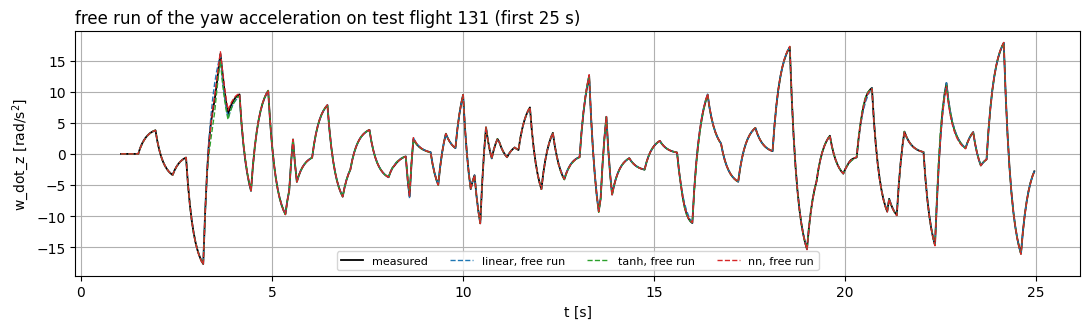

In [7]:
r = runs[test[0]]; s = (r.t > 1) & (r.t < 25)
plt.figure(figsize=(11, 3.4))
plt.plot(r.t[s], r.w_dot_z[s], 'k', lw=1.3, label='measured')
for kind, c in (('linear', 'C0'), ('tanh', 'C2'), ('nn', 'C3')):
    plt.plot(r.t[s], res[kind][s], '--', color=c, lw=1, label=f'{kind}, free run')
plt.xlabel('t [s]'); plt.ylabel('w_dot_z [rad/s$^2$]'); plt.legend(ncol=4, fontsize=8)
plt.title(f'free run of the yaw acceleration on test flight {test[0] + 1} (first 25 s)', loc='left')
plt.tight_layout(); plt.show()

## 5. Does the yaw gain depend on the thrust?

Settled acceleration for a small constant $\delta$, as a function of `u_coll`, against the gain measured
directly in the data (least squares in bins of `u_coll`). The linear model cannot see `u_coll`; the tanh
model imposes $\propto 1 - \tanh^2(u_{coll})$; the network has to find the dependency on its own.

u_coll in [-0.4, +0.1):   3064 samples, measured gain  232.6 rad/s^2 per unit
u_coll in [+0.1, +0.3):   5828 samples, measured gain  194.3 rad/s^2 per unit
u_coll in [+0.3, +0.5): 112729 samples, measured gain  172.6 rad/s^2 per unit
u_coll in [+0.5, +0.6):   5943 samples, measured gain  158.4 rad/s^2 per unit
u_coll in [+0.6, +1.0):   4436 samples, measured gain  125.1 rad/s^2 per unit


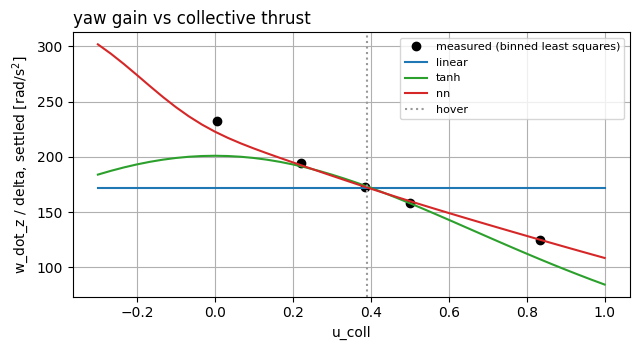

In [8]:
D = np.vstack([np.column_stack([*features(runs[i], 'nn')[0].T, features(runs[i], 'nn')[1]]) for i in train])
bins = [(-0.4, 0.1), (0.1, 0.3), (0.3, 0.45), (0.45, 0.6), (0.6, 1.0)]
u_mid, gain = [], []
for lo, hi in bins:
    s = (D[:, 2] >= lo) & (D[:, 2] < hi)
    th = np.linalg.lstsq(D[s][:, :2], D[s][:, 3], rcond=None)[0]
    u_mid.append(np.median(D[s, 2])); gain.append(th[1] / (1 - th[0]))
    print(f'u_coll in [{lo:+.1f}, {hi:+.1f}): {s.sum():6d} samples, measured gain {gain[-1]:6.1f} rad/s^2 per unit')

ug = np.linspace(-0.3, 1.0, 40); d0 = 0.02
def settled(kind, u):
    a = 0.0
    for _ in range(80):                              # iterate to the fixed point a = F(a, d0, u)
        a = predict(kind, x_of(kind, a, d0, u))[0]
    return a / d0

plt.figure(figsize=(6.5, 3.6))
plt.plot(u_mid, gain, 'ko', label='measured (binned least squares)')
for kind, c in (('linear', 'C0'), ('tanh', 'C2'), ('nn', 'C3')):
    plt.plot(ug, [settled(kind, u) for u in ug], color=c, label=kind)
plt.axvline(0.39, color='0.6', ls=':', label='hover')
plt.xlabel('u_coll'); plt.ylabel('w_dot_z / delta, settled [rad/s$^2$]'); plt.legend(fontsize=8)
plt.title('yaw gain vs collective thrust', loc='left'); plt.tight_layout(); plt.show()

## 6. Save the model for the yaw environment

In [9]:
import joblib
joblib.dump({'net': net, 'sx': sx, 'sy': sy, 'theta_linear': theta['linear'], 'theta_tanh': theta['tanh'],
             'Ts': Ts, 'inputs_nn': ['w_dot_z[k-1]', 'delta[k-1]', 'u_coll[k-1]'], 'output': 'w_dot_z[k]',
             'flip': FLIP, 'use': 'w_dot_z = (F(x) - F(x * flip)) / 2,  F(x) = sy^-1(net(sx(x)))  (antisymmetric)'},
            'drone_yaw_nn.joblib')
print('saved drone_yaw_nn.joblib')

def step_model(a_prev, delta_prev, u_prev):
    return float(nn_predict(np.array([[a_prev, delta_prev, u_prev]]))[0])
print('check: at rest ->', step_model(0.0, 0.0, 0.39), ' | delta = 0.05 at hover, settled ->',
      round(settled('nn', 0.39) * 0.05, 2), 'rad/s^2')

saved drone_yaw_nn.joblib
check: at rest -> 0.0  | delta = 0.05 at hover, settled -> 8.62 rad/s^2


## 7. Conclusions

1. **Same structure as the altitude.** $\dot w_z[k] = 0.779\,\dot w_z[k-1] + 38.1\,\delta[k-1]$: one sample of
   input delay, one lag, pole $0.779$ ($\tau = 0.20$ s, the time constant of the thrust: same motors).
   Predicting the acceleration and integrating $w_z$, $\psi$ (known physics) keeps the learned part small
   and stable: the free run of $\dot w_z$ over 60 s stays within **3 %** of its spread for every model.

2. **The yaw gain depends on the thrust**: 233 rad/s$^2$ per unit of $\delta$ at $u_{coll} \approx 0$, 173 at
   hover, 125 at $u_{coll} \approx 0.8$ (least squares in bins of the data). The linear model is exact only
   at hover, where 85 % of the data are.

3. **The tanh model has the right idea but the wrong shape.** $\tanh(u+\delta) - \tanh(u-\delta)$ gives a gain
   maximal at $u_{coll} = 0$ and symmetric around it; the data keep increasing below 0. The motor
   nonlinearity is therefore not only the `tanh` of each input (an offset, or a thrust law after it), and
   imposing a wrong structure makes it the worst model on the 2 s prediction of $\psi$.

4. **The neural network is the best model** on every test (one-step error halved, free run 0.13-0.14
   rad/s$^2$ against 0.20-0.23, $\psi$ within 2 deg after 1 s), and the only one that recovers the measured
   gain curve on its own, with 81 parameters. One physical constraint was needed: **antisymmetry**
   ($-\delta$ turns the other way), imposed by mirror-image data and by construction, so that it has no bias
   at rest. Below $u_{coll} \approx 0$ it extrapolates (few data there): keep the yaw manoeuvre at hover thrust.

5. **$\psi$ cannot be predicted in open loop for long** (double integrator, no restoring force): 2-3 deg after
   1 s, 9-13 deg after 2 s. That is fine for a model used inside a closed loop, and it says what the yaw
   policy must learn: actively brake the rotation, since nothing else will stop it.

### For the yaw environment (RL)

`drone_yaw_nn.joblib` is the yaw plant, used exactly like `drone_model_nn.joblib` for the altitude. Inside `step()`:

```
a1  = (F(x) - F(x * flip)) / 2,   x = (a0, delta_prev, u_coll_prev)    # w_dot_z, one sample of delay
psi = psi + Ts * wz + Ts**2 * (2 * a0 + a1) / 6                         # same integration as z
wz  = wz + Ts * (a0 + a1) / 2
```

Action range: $|\delta| \le 0.15$ (the identified range; 0.05 already gives ~9 rad/s$^2$ at hover).